# TP3 – Aprendizaje No Supervisado: PCA, selección de variables y K-means

**Objetivo:** comparar tres formas de agrupar los mismos datos con K-means: (1) todas las variables estandarizadas, (2) las dos primeras componentes principales y (3) un subconjunto de variables obtenido por análisis de correlación.

**Autor:** Santiago · Economía, UNAULA

**Dataset:** *Wine Recognition* (UCI Machine Learning Repository; también disponible en Kaggle). Contiene análisis químicos de 178 vinos italianos de tres cultivares. Se carga con `sklearn.datasets.load_wine`. Las etiquetas de cultivar **no se usan** para entrenar; solo al final como validación externa.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
RS = 42

## A. Selección del dataset

In [2]:
wine = load_wine(as_frame=True)
df_full = wine.frame
vars_sel = ['alcohol','malic_acid','alcalinity_of_ash','magnesium','total_phenols',
            'flavanoids','color_intensity','hue','proline']
X = df_full[vars_sel].copy()
y_true = df_full['target']          # solo para validación externa al final
print(X.shape, '| valores faltantes:', int(X.isna().sum().sum()))
X.describe().T.round(2)

(178, 9) | valores faltantes: 0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00
hue,178.0,0.96,0.23,0.48,0.78,0.96,1.12,1.71
proline,178.0,746.89,314.91,278.00,500.50,673.50,985.00,1680.00


El dataset cumple los criterios: **9 variables numéricas** (entre 5 y 10), sin valores faltantes, sin variables categóricas y sin columnas irrelevantes (se descartaron `ash`, `nonflavanoid_phenols`, `proanthocyanins` y `od280/od315_of_diluted_wines` para quedar dentro del rango y evitar variables muy solapadas de entrada).

## B. Preparación del dataset

| Variable | Qué mide | Por qué es relevante |
|---|---|---|
| `alcohol` | % de alcohol | Cuerpo y estilo del vino |
| `malic_acid` | Ácido málico | Acidez / frescura |
| `alcalinity_of_ash` | Alcalinidad de las cenizas | Perfil mineral |
| `magnesium` | Magnesio | Perfil mineral |
| `total_phenols` | Fenoles totales | Antioxidantes, estructura |
| `flavanoids` | Flavonoides | Principal subgrupo de fenoles; muy discriminante entre cultivares |
| `color_intensity` | Intensidad de color | Proxy de maduración y tipo de uva |
| `hue` | Tono | Relación entre colores amarillo/azul/rojo |
| `proline` | Prolina (aminoácido) | Muy asociado al cultivar |

Las variables están en escalas muy distintas (la prolina está en cientos y el tono en décimas), por lo que **estandarizamos**: tanto PCA como K-means dependen de distancias/varianzas y sin escalar dominaría la prolina.

In [3]:
scaler = StandardScaler()
X_sc = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X_sc.describe().loc[['mean','std']].round(2)

,alcohol,malic_acid,alcalinity_of_ash,magnesium,total_phenols,flavanoids,color_intensity,hue,proline
mean,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## C. Reducción de dimensionalidad con PCA

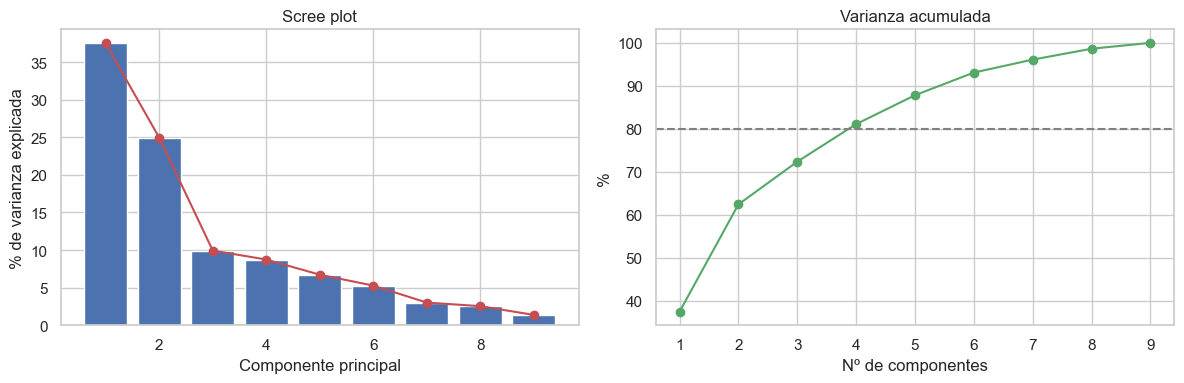

,% varianza,% acumulada
PC1,37.48,37.48
PC2,24.95,62.44
PC3,9.94,72.37
PC4,8.73,81.11
PC5,6.72,87.83
PC6,5.27,93.10
PC7,3.01,96.10
PC8,2.53,98.63
PC9,1.37,100.00


In [4]:
pca_full = PCA(random_state=RS).fit(X_sc)
ev = pca_full.explained_variance_ratio_ * 100
cum = np.cumsum(ev)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(ev)+1), ev, color='#4C72B0')
ax[0].plot(range(1, len(ev)+1), ev, 'o-', color='#C44E52')
ax[0].set(title='Scree plot', xlabel='Componente principal', ylabel='% de varianza explicada')
ax[1].plot(range(1, len(ev)+1), cum, 'o-', color='#55A868')
ax[1].axhline(80, ls='--', c='gray'); ax[1].set(title='Varianza acumulada', xlabel='Nº de componentes', ylabel='%')
plt.tight_layout(); plt.show()
pd.DataFrame({'% varianza': ev.round(2), '% acumulada': cum.round(2)}, index=[f'PC{i}' for i in range(1, len(ev)+1)])

Varianza explicada por PC1+PC2: 62.4%


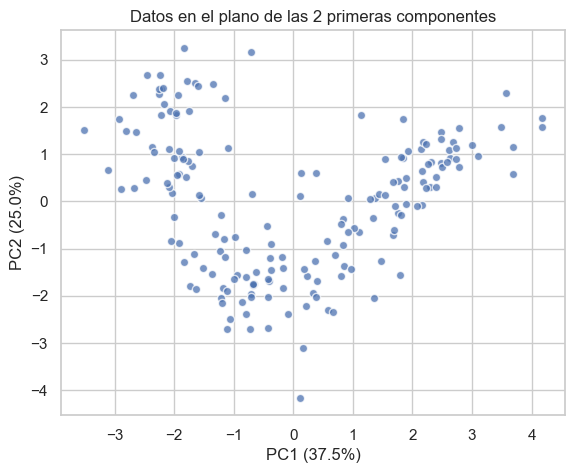

,PC1,PC2
alcohol,0.25,0.49
malic_acid,-0.29,0.31
alcalinity_of_ash,-0.32,-0.04
magnesium,0.20,0.24
total_phenols,0.45,-0.04
flavanoids,0.47,-0.11
color_intensity,-0.02,0.58
hue,0.34,-0.40
proline,0.41,0.31


In [5]:
pca2 = PCA(n_components=2, random_state=RS)
X_pca = pca2.fit_transform(X_sc)
print(f'Varianza explicada por PC1+PC2: {pca2.explained_variance_ratio_.sum()*100:.1f}%')

plt.figure(figsize=(6.5, 5))
plt.scatter(X_pca[:,0], X_pca[:,1], s=35, alpha=.75, color='#4C72B0', edgecolor='white')
plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)'); plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('Datos en el plano de las 2 primeras componentes'); plt.show()

loadings = pd.DataFrame(pca2.components_.T, index=X.columns, columns=['PC1','PC2']).round(2)
loadings

**Interpretación.**
- Las dos primeras componentes explican **62,4 %** de la varianza (PC1 37,5 % + PC2 25,0 %). El scree plot muestra un codo después de PC2–PC3, y se necesitan 4 componentes para superar el 80 %.
- **PC1** se asocia con flavonoides, fenoles totales, prolina y tono (positivo) y con acidez málica y alcalinidad de las cenizas (negativo): resume el contenido fenólico/estructura del vino. **PC2** está dominada por intensidad de color, alcohol y prolina.
- En el diagrama de dispersión se distinguen agrupamientos bastante separados a lo largo de PC1 y PC2, lo que anticipa que K-means encontrará estructura en 2D. Al conservar solo 62 % de la varianza se pierde información, algo que se evalúa en la sección E.

## D. Selección de variables por correlación

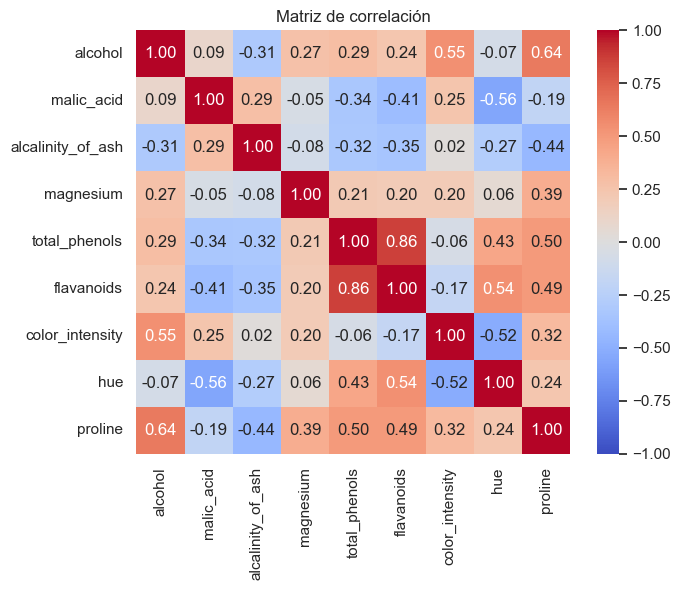

Pares con |r| > 0.7
total_phenols  flavanoids    0.86
dtype: float64


In [6]:
corr = X_sc.corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación'); plt.show()

THR = 0.70
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pares = upper.stack().loc[lambda s: s > THR].sort_values(ascending=False)
print('Pares con |r| >', THR); print(pares.round(2))

In [7]:
# Criterio: de cada par con |r| > THR se elimina la variable con mayor correlación media absoluta con el resto
mean_abs = corr.abs().mean()
drop = set()
for (a, b) in pares.index:
    if a in drop or b in drop: continue
    drop.add(a if mean_abs[a] > mean_abs[b] else b)
sel_vars = [v for v in X.columns if v not in drop]
print('Eliminadas:', sorted(drop)); print('Conservadas:', sel_vars)
X_sel = X_sc[sel_vars]

Eliminadas: ['flavanoids']
Conservadas: ['alcohol', 'malic_acid', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'color_intensity', 'hue', 'proline']


**Criterio:** se calculó la matriz de correlación y se fijó un umbral de |r| > 0,70 para considerar dos variables redundantes. Solo un par lo supera: `total_phenols`–`flavanoids` (r = 0,86). De ese par se elimina la variable con **mayor correlación absoluta media con el resto** (`flavanoids`), porque es la que aporta menos información no compartida. Se conservan **8 variables**.

*Nota:* `flavanoids` es muy discriminante entre cultivares, así que eliminarla es un costo potencial que se revisa en los resultados.

## E. K-means sobre las tres versiones

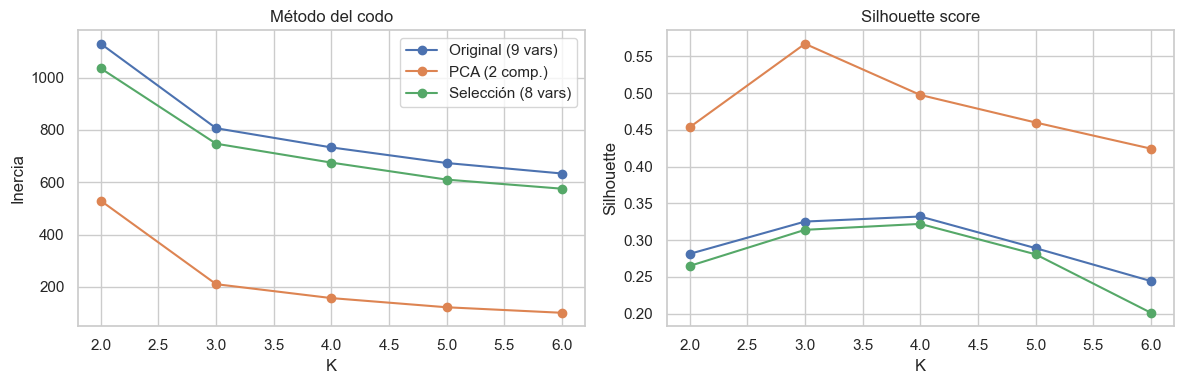

In [8]:
versiones = {'Original (9 vars)': X_sc.values,
             'PCA (2 comp.)': X_pca,
             f'Selección ({len(sel_vars)} vars)': X_sel.values}
Ks = range(2, 7)
filas = []
for nombre, datos in versiones.items():
    for k in Ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(datos)
        filas.append({'Enfoque': nombre, 'K': k, 'Inercia': km.inertia_,
                      'Silhouette': silhouette_score(datos, km.labels_),
                      'ARI vs cultivar': adjusted_rand_score(y_true, km.labels_)})
res = pd.DataFrame(filas)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nombre in versiones:
    s = res[res.Enfoque == nombre]
    ax[0].plot(s.K, s.Inercia, 'o-', label=nombre)
    ax[1].plot(s.K, s.Silhouette, 'o-', label=nombre)
ax[0].set(title='Método del codo', xlabel='K', ylabel='Inercia'); ax[1].set(title='Silhouette score', xlabel='K', ylabel='Silhouette')
ax[0].legend(); plt.tight_layout(); plt.show()

In [9]:
tabla = res.pivot(index='K', columns='Enfoque', values=['Silhouette','Inercia']).round(3)
display(tabla)
print('\nValidación externa (ARI frente al cultivar real, no usado en el entrenamiento):')
display(res.pivot(index='K', columns='Enfoque', values='ARI vs cultivar').round(3))

Silhouette                                            Inercia  \
Enfoque Original (9 vars) PCA (2 comp.) Selección (8 vars) Original (9 vars)   
K                                                                              
2                   0.281         0.454              0.265          1129.089   
3                   0.325         0.567              0.314           806.337   
4                   0.332         0.497              0.322           732.957   
5                   0.289         0.460              0.281           673.341   
6                   0.244         0.424              0.201           633.270   

                                          
Enfoque PCA (2 comp.) Selección (8 vars)  
K                                         
2             529.151           1035.011  
3             210.327            747.212  
4             157.121            674.892  
5             122.062            609.948  
6             100.932            575.205


Validación externa (ARI frente al cultivar real, no usado en el entrenamiento):


Enfoque,Original (9 vars),PCA (2 comp.),Selección (8 vars)
K,,,
2,0.423,0.423,0.436
3,0.866,0.801,0.802
4,0.867,0.675,0.820
5,0.699,0.576,0.689
6,0.609,0.505,0.555


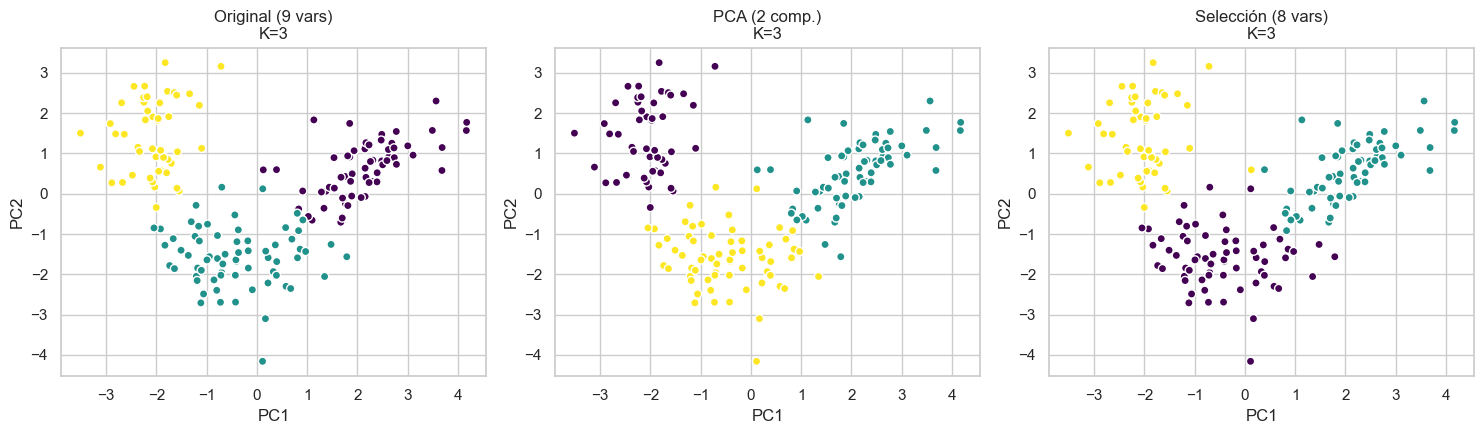

In [9]:
# Visualización de K=3 en el plano PCA para cada enfoque
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, (nombre, datos) in zip(ax, versiones.items()):
    lab = KMeans(n_clusters=3, n_init=10, random_state=RS).fit_predict(datos)
    a.scatter(X_pca[:,0], X_pca[:,1], c=lab, cmap='viridis', s=35, edgecolor='white')
    a.set_title(f'{nombre}\nK=3'); a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.tight_layout(); plt.show()

### Análisis de resultados

**Elbow.** Con PCA (2 comp.) la inercia cae de 529 (K=2) a 210 (K=3) y luego se aplana (157 en K=4): codo claro en **K=3**. Con las versiones de 9 y 8 variables la curva es más suave y el codo es menos nítido, también alrededor de K=3–4.

**Silhouette.** PCA obtiene los valores más altos (0,567 en K=3), frente a 0,325 (original) y 0,314 (selección) en K=3. En las versiones de 9 y 8 variables el máximo es K=4 por muy poco (0,332 y 0,322), una diferencia pequeña respecto de K=3.

**Cautela al comparar.** El silhouette no es estrictamente comparable entre espacios de distinta dimensión: en 2D las distancias se concentran y los grupos *parecen* más compactos, en parte porque se descartó 37,6 % de la varianza. Por eso se agregó el **ARI frente al cultivar real** (que no se usó para entrenar) como validación externa:

- K=3: original **0,866**, PCA 0,801, selección 0,802.
- La selección de variables apenas cambia el resultado respecto del original (silhouette y ARI casi idénticos), lo que confirma que `flavanoids` era en gran parte redundante con `total_phenols`.
- PCA pierde algo de fidelidad (ARI 0,80 vs 0,87), pero sigue recuperando bien la estructura real.

### Enfoque más apropiado

**K=3 con PCA de 2 componentes** es el más apropiado para *explorar e interpretar*: tiene el codo más claro, el mayor silhouette y permite visualizar los grupos directamente. K=3 además coincide con los tres cultivares reales. Como contrapartida, el clustering sobre las **9 variables originales** es el más fiel a los datos (mejor ARI, 0,87), y la selección por correlación logra casi lo mismo con una variable menos. Si el objetivo fuera maximizar la calidad del agrupamiento y no la visualización, usaría las variables originales (o la selección) con K=3.

**Limitaciones:** dataset pequeño (178 observaciones), K-means asume grupos esféricos y es sensible a la inicialización (se usó `n_init=10` y semilla fija), y la selección por correlación solo considera redundancia lineal entre pares.